# 04 · Análisis supervisado: Regresión
**Unidad III · Fase CRISP-DM:** 4. Modelado y 5. Evaluación

**Objetivo:** predecir el número de anillos (**Rings**), y con ello la edad (Rings + 1.5 años), a partir de las medidas físicas.

🧠 **Regresión** = predecir un **número**. El modelo aprende de abulones cuya edad ya conocemos y después estima la de abulones nuevos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")
RUTA_PROC = Path("..") / "data" / "processed" / "abalone_limpio.csv"
RUTA_FIG = Path("..") / "docs" / "figuras"
RUTA_MOD = Path("..") / "modelos"
RUTA_FIG.mkdir(parents=True, exist_ok=True)
RUTA_MOD.mkdir(exist_ok=True)

SEMILLA = 42   # fija el azar para que los resultados sean siempre iguales

df = pd.read_csv(RUTA_PROC)
NUMERICAS = ["Length", "Diameter", "Height", "Whole_weight",
             "Shucked_weight", "Viscera_weight", "Shell_weight"]
CATEGORICAS = ["Sex"]
X = df[NUMERICAS + CATEGORICAS]
print("Registros:", len(df))
y = df["Rings"]

Registros: 4169


## 1. Separar datos de entrenamiento y de prueba
- **Entrenamiento (80%)**: el modelo aprende con estos datos.
- **Prueba (20%)**: datos que el modelo **nunca vio**; sirven para medir qué tan bien predice de verdad.

Es como estudiar con unos ejercicios y presentar el examen con ejercicios distintos.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Entrenamiento: (3335, 8) | Prueba: (834, 8)


## 2. Preprocesamiento
Los modelos solo entienden números, así que hay que transformar `Sex` y escalar las medidas.

In [3]:
# Preprocesamiento:
#  - Sex (texto) -> OneHotEncoder la convierte en 3 columnas de 0/1 (Sex_F, Sex_I, Sex_M)
#  - Medidas numéricas -> StandardScaler las pone en la misma escala (media 0, desviación 1)
preprocesador = ColumnTransformer([
    ("num", StandardScaler(), NUMERICAS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
])

## 3. Modelos a comparar
| Modelo | Idea en una frase |
|---|---|
| **Regresión lineal** | Busca la recta (o plano) que mejor relaciona las medidas con Rings. Simple y fácil de explicar. |
| **Árbol de decisión** | Hace preguntas tipo "¿el peso de la concha es mayor a X?" hasta llegar a una predicción. |
| **Random Forest** | Muchos árboles distintos "votan" y se promedia su respuesta. Suele ser más preciso. |

Cada modelo va dentro de un **Pipeline** (preprocesamiento + modelo), así el escalado se aprende solo con los datos de entrenamiento.

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

modelos = {
    "Regresión lineal": LinearRegression(),
    "Árbol de decisión": DecisionTreeRegressor(max_depth=6, random_state=SEMILLA),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                           random_state=SEMILLA, n_jobs=-1),
}

resultados = []
pipelines = {}
for nombre, modelo in modelos.items():
    pipe = Pipeline([("prep", preprocesador), ("modelo", modelo)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    pipelines[nombre] = pipe
    resultados.append({
        "Modelo": nombre,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R²": r2_score(y_test, pred),
    })

tabla = pd.DataFrame(resultados).round(3)
tabla

,Modelo,MAE,RMSE,R²
0,Regresión lineal,1.517,2.110,0.616
1,Árbol de decisión,1.664,2.387,0.509
2,Random Forest,1.493,2.132,0.609


## 4. ¿Cómo se leen las métricas?
- **MAE** (error absoluto medio): en promedio, **¿por cuántos anillos se equivoca?** Menor es mejor.
- **RMSE**: parecido al MAE, pero castiga más los errores grandes. Menor es mejor.
- **R²**: qué porcentaje de la variación de la edad explica el modelo (de 0 a 1). Mayor es mejor.

In [5]:
# Modelo de referencia (baseline): predecir siempre el promedio.
# Si un modelo no supera esto, no sirve.
pred_base = np.full(len(y_test), y_train.mean())
print(f"Baseline (siempre el promedio) -> MAE: {mean_absolute_error(y_test, pred_base):.3f}")

Baseline (siempre el promedio) -> MAE: 2.519


## 5. Optimización del mejor modelo (validación cruzada)
🧠 **GridSearchCV** prueba varias combinaciones de configuración (*hiperparámetros*) y elige la mejor. Usa **validación cruzada de 5 partes**: divide el entrenamiento en 5, entrena con 4 y valida con 1, rotando. Así la elección no depende de la suerte.

In [6]:
from sklearn.model_selection import GridSearchCV

pipe_rf = Pipeline([("prep", preprocesador),
                    ("modelo", RandomForestRegressor(random_state=SEMILLA, n_jobs=-1))])
parametros = {
    "modelo__n_estimators": [100, 200],
    "modelo__min_samples_leaf": [3, 5, 10],
    "modelo__max_features": [0.5, 1.0],
}
busqueda = GridSearchCV(pipe_rf, parametros, cv=5,
                        scoring="neg_mean_absolute_error", n_jobs=-1)
busqueda.fit(X_train, y_train)

print("Mejores parámetros:", busqueda.best_params_)
mejor = busqueda.best_estimator_
pred = mejor.predict(X_test)
print(f"Random Forest optimizado -> MAE: {mean_absolute_error(y_test, pred):.3f} | "
      f"RMSE: {np.sqrt(mean_squared_error(y_test, pred)):.3f} | R²: {r2_score(y_test, pred):.3f}")

Mejores parámetros: {'modelo__max_features': 0.5, 'modelo__min_samples_leaf': 10, 'modelo__n_estimators': 200}
Random Forest optimizado -> MAE: 1.486 | RMSE: 2.122 | R²: 0.612


## 6. Gráfica: valor real vs. predicho
Si el modelo fuera perfecto, todos los puntos estarían sobre la línea roja.

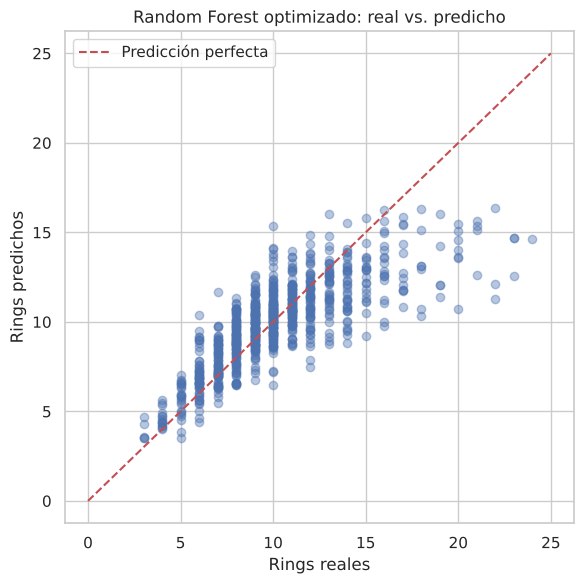

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, pred, alpha=0.4)
lim = [0, max(y_test.max(), pred.max()) + 1]
ax.plot(lim, lim, "r--", label="Predicción perfecta")
ax.set_xlabel("Rings reales")
ax.set_ylabel("Rings predichos")
ax.set_title("Random Forest optimizado: real vs. predicho")
ax.legend()
plt.tight_layout()
plt.savefig(RUTA_FIG / "08_regresion_real_vs_pred.png", dpi=120)
plt.show()

👀 El modelo predice bien a los abulones jóvenes y de edad media, pero **tiende a subestimar a los muy viejos** (los puntos de la derecha quedan debajo de la línea): después de cierta edad el abulón casi deja de crecer, así que su tamaño ya no "delata" su edad.

## 7. ¿Qué variables usa más el modelo?

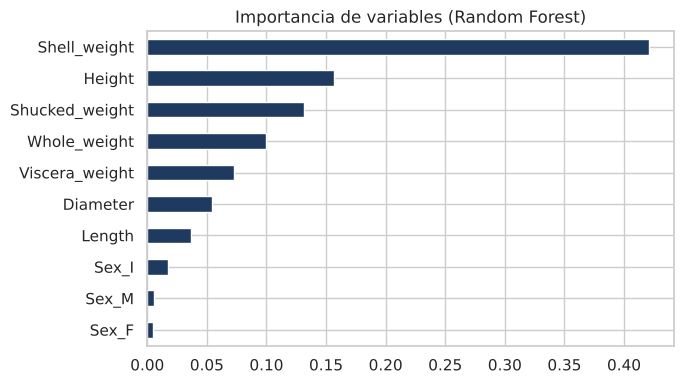

In [8]:
nombres = mejor.named_steps["prep"].get_feature_names_out()
importancias = pd.Series(mejor.named_steps["modelo"].feature_importances_, index=nombres)
importancias.index = [n.split("__")[1] for n in importancias.index]
importancias = importancias.sort_values()

importancias.plot(kind="barh", figsize=(7, 4), color="#1F3A5F")
plt.title("Importancia de variables (Random Forest)")
plt.tight_layout()
plt.savefig(RUTA_FIG / "09_importancia_regresion.png", dpi=120)
plt.show()

## 8. Guardar resultados y modelo

In [9]:
tabla.to_csv(Path("..") / "docs" / "metricas_regresion.csv", index=False, encoding="utf-8-sig")
joblib.dump(mejor, RUTA_MOD / "regresion_random_forest.joblib", compress=3)
print("Guardado: docs/metricas_regresion.csv y modelos/regresion_random_forest.joblib")

Guardado: docs/metricas_regresion.csv y modelos/regresion_random_forest.joblib


## 9. Conclusiones
- Todos los modelos superan claramente al baseline (predecir siempre el promedio).
- El **Random Forest optimizado** obtiene el menor error: se equivoca en promedio en **alrededor de 1.5 anillos** (≈ 1.5 años).
- **Shell_weight** (peso de la concha) es la variable más importante, lo que coincide con el EDA.
- Limitación: el modelo subestima la edad de los abulones más viejos.